<a href="https://colab.research.google.com/github/eojin22/ESAA/blob/main/OB_WEEK13_1_Kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Networks in Tensorflow with Titanic

## Overview
- How to Prepare Data for a Kaggle Competition
- Using sklearn preprocessing features with pipelines
- Intro to Using Tensorflow
- Writing a Custom Callback
- Making a Submission!

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 5GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## Reading the Data

In [2]:
train_df = pd.read_csv('/content/train.csv')

In [3]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
train_df.loc[0]

,0
PassengerId,1
Survived,0
Pclass,3
Name,"Braund, Mr. Owen Harris"
Sex,male
Age,22.0
SibSp,1
Parch,0
Ticket,A/5 21171
Fare,7.25


In [5]:
#Drop Name and Ticket
train_df.drop(['Name', 'Ticket', 'PassengerId', 'Cabin'], axis=1, inplace=True)
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [6]:
# split train_df into X and y
X=train_df.drop('Survived',axis=1,inplace=False)
y=train_df['Survived']

print(f'Input features shape: {X.shape}')
print(f'Labels shape: {y.shape}')

Input features shape: (891, 7)
Labels shape: (891,)


## Data Analysis

In [7]:
#Import visualization libraries

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

Text(0, 0.5, 'Number of Passengers')

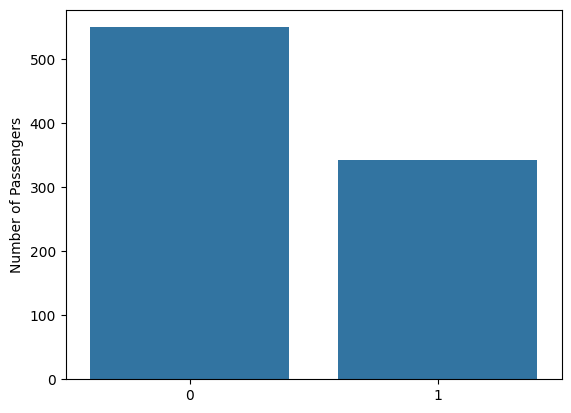

In [8]:
sns.barplot(x=y.unique(),y=y.value_counts())
plt.ylabel('Number of Passengers')

   Pclass  Sex  Age  SibSp  Parch  Fare  Embarked
0     891  891  714    891    891   891       889


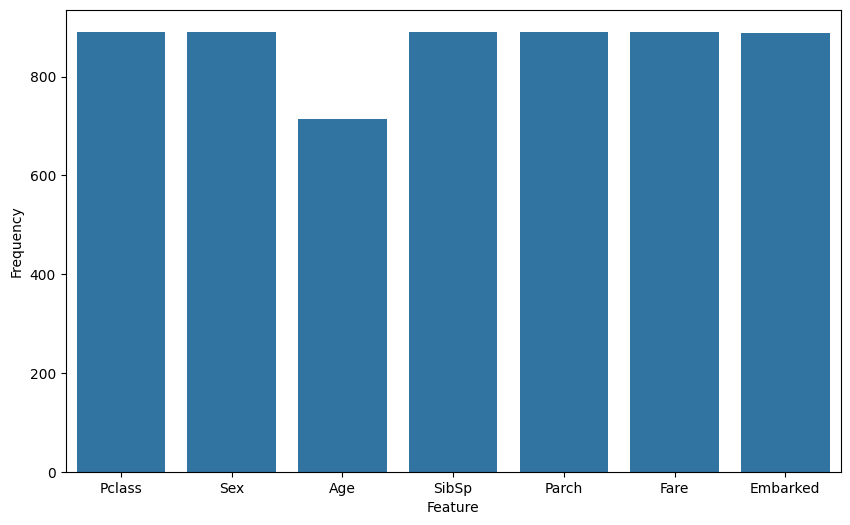

In [9]:
frequencies=X.count()

freq_df=pd.DataFrame([frequencies],columns=X.columns)
print(freq_df.head())

plt.figure(figsize=(10,6))
sns.barplot(x=X.columns,y=frequencies)
plt.ylabel('Frequency')
plt.xlabel('Feature')
plt.show()

## Imputing and One-Hot Encoding

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

'''
The following pipeline is only for numerical features:
1. Fill in Missing Values with Median value of existing numbers
2. Scale all the numbers to be in between 0 and 1
'''

num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy="median")),
    ('std_scaler',StandardScaler())
])

'''
The following pipeline is only for categorical features:
1. Fill in Missing Values with Most Frequent value from existing data
2. One-hot encode (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
'''

cat_pipeline=Pipeline([
    ('cat_imputer',SimpleImputer(strategy='most_frequent')),
    ('one_hot',OneHotEncoder())
])

In [11]:
# Combine Pipelines

from sklearn.compose import ColumnTransformer

num_attribs=['Age','SibSp','Parch','Fare']
cat_attribs=['Pclass','Sex','Embarked']

full_pipeline=ColumnTransformer([("num",num_pipeline,num_attribs),
                                ("cat", cat_pipeline, cat_attribs)])
X=full_pipeline.fit_transform(X)
X.shape

(891, 12)

In [12]:
from sklearn.model_selection import train_test_split

X_train,X_val,y_train,y_val=train_test_split(X,y,test_size=0.2,random_state=42)

## Neural Network

In [13]:
# Import necessary libraries

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers as L

Creating neural networks is pretty simple in tensorflow. Here are the steps:

1. Define Sequential model model = Sequential()
2. Add Input Layer model.add(L.InputLayer(input_shape=...)) --> Optional!
3. Add fully connected layers model.add(L.Dense(...))
4. Compile Model
5. Callbacks (if necessary)
6. Train Model

In [14]:
#Step 1
model=Sequential(name='titanic_model')

#Step 2
model.add(L.InputLayer(input_shape=(12,))) # necessary to use model.summary()

#Step 3
model.add(L.Dense(512,activation='relu'))
model.add(L.Dense(1024,activation='relu'))
model.add(L.Dropout(0.4)) #prevents overfitting by setting 40% of nuerons to 0
model.add(L.Dense(512,activation='relu'))
model.add(L.Dropout(0.4))
model.add(L.Dense(128,activation='relu'))
model.add(L.Dense(64,activation='relu'))
model.add(L.Dense(64,activation='relu'))
model.add(L.Dense(1,activation='sigmoid')) # output layer, use sigmoid for binary

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "titanic_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,134,913 (4.33 MB)

 Trainable params: 1,134,913 (4.33 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
#Step 4
model.compile(loss='binary_crossentropy',optimizer=keras.optimizers.Adam(0.0001),metrics=['accuracy'])


In [16]:
'''
This custom callback stops training once the validation accuracy reaches 83%.
There are several callbacks already implemented by keras.
https://www.tensorflow.org/api_docs/python/tf/keras/callbacks

'''

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self,epoch,logs={}):
        if(logs.get('val_accuracy')>0.83):
            print("\nReached 83% accuracy so cancelling training!")
            self.model.stop_training=True

#Step 6
history=model.fit(X_train,y_train,
                  validation_data=(X_val,y_val),
                  batch_size=8,
                  callbacks=[myCallback()],
                  epochs=50)

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.6348 - loss: 0.6341 - val_accuracy: 0.7151 - val_loss: 0.5508
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7865 - loss: 0.5070 - val_accuracy: 0.8101 - val_loss: 0.4577
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8174 - loss: 0.4429 - val_accuracy: 0.7989 - val_loss: 0.4370
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8146 - loss: 0.4348 - val_accuracy: 0.8156 - val_loss: 0.4338
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8174 - loss: 0.4269 - val_accuracy: 0.8268 - val_loss: 0.4293
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8272 - loss: 0.4150 - val_accuracy: 0.8212 - val_loss: 0.4393
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8287 - loss: 0.4005 - val_accuracy: 0.8212 - val_loss: 0.4492
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8301 - loss: 0.3982 - val_accuracy: 0.8268 - v

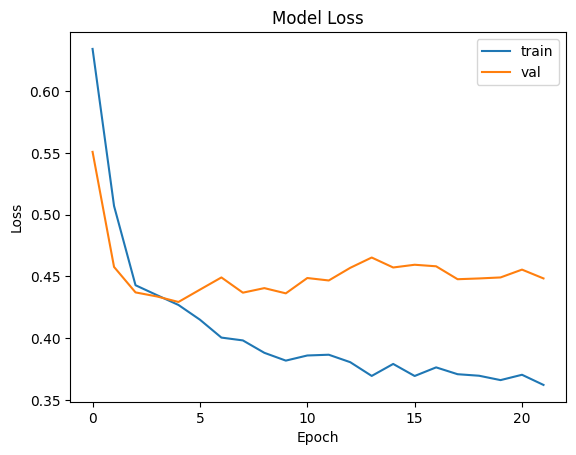

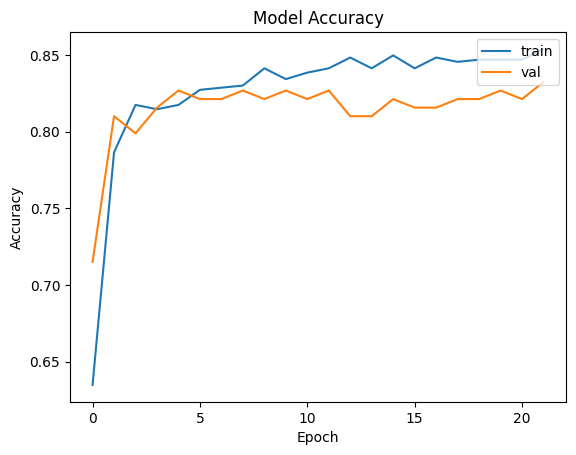

In [17]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(['train','val'],loc='upper right')
plt.show()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['train','val'],loc='upper right')
plt.show()

## Prepare the Test Data

In [23]:
test_df=pd.read_csv('test.csv')
test_df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1,inplace=True)
test_df

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,34.5,0,0,7.8292,Q
1,3,female,47.0,1,0,7.0000,S
2,2,male,62.0,0,0,9.6875,Q
3,3,male,27.0,0,0,8.6625,S
4,3,female,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...
413,3,male,NaN,0,0,8.0500,S
414,1,female,39.0,0,0,108.9000,C
415,3,male,38.5,0,0,7.2500,S
416,3,male,NaN,0,0,8.0500,S


In [19]:
test_prepared=full_pipeline.transform(test_df)
test_prepared.shape

(418, 12)

In [20]:
preds=model.predict(test_prepared)
preds[:5]

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


array([[0.07376771],
       [0.40223563],
       [0.05007419],
       [0.12064566],
       [0.3263428 ]], dtype=float32)

In [21]:
submission=pd.read_csv('gender_submission.csv')
submission['Survived'] = [0 if pred < 0.5 else 1 for pred in preds]
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [22]:
from IPython.display import FileLink

submission.to_csv('submission.csv',index=False)
FileLink(r'submission.csv')

/content/submission.csv